# Local Search 2-8-8-1 — Classification Disque
Equivalent Python du script Cadence `cadence_sa_direct.py`.  
Utilise les tables de caractérisation au lieu de Spectre → **quelques secondes** au lieu de plusieurs heures.

**Architecture :** 2 entrées (Vx, Vy) → 8 C1 → 8 C2 → 1 sortie  
**Problème :** classifier si le point (x,y) est **intérieur** (r < 0.5) ou **extérieur** (r > 0.5)  
**Algorithme :** Local search synapse par synapse depuis W_MIN (même logique que l'original Cadence)


In [37]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import time, warnings
warnings.filterwarnings('ignore')

%matplotlib inline
plt.rcParams['figure.dpi'] = 110
plt.rcParams['font.size']  = 11
np.set_printoptions(precision=4, suppress=True)
print("Imports OK")


Imports OK


In [38]:
# ── Chemins vers les CSV (adapter si nécessaire) ──
INPUT_CSV   = 'input_min_conso.csv'
NEURON_CSV  = 'neuron.csv'
SYN_EXC_CSV = 'excitation20.csv'
SYN_INH_CSV = 'inhibition20.csv'

def read_cadence_rows(csv_path):
    df = pd.read_csv(csv_path)
    data_cols = [c for c in df.columns if c not in ['Parameter', 'Unnamed: 1']]
    def get_row(row_name):
        row = df.loc[df['Parameter'] == row_name, data_cols]
        if row.empty: raise ValueError(f"'{row_name}' introuvable dans {csv_path}")
        return pd.to_numeric(row.iloc[0], errors='coerce').to_numpy(dtype=float)
    return get_row

inp = read_cadence_rows(INPUT_CSV)
INPUT_V_AXIS = inp('Vex')
INPUT_F_AXIS = inp('Fspikes')

neu = read_cadence_rows(NEURON_CSV)
NEURON_I_AXIS = neu('Iex')
NEURON_F_AXIS = neu('Fspikes')

exc = read_cadence_rows(SYN_EXC_CSV)
EXC_W2    = exc('W2')
EXC_FPRE  = exc('Fpre')
EXC_IPOST = exc('Ipost')

inh = read_cadence_rows(SYN_INH_CSV)
INH_W2    = inh('W2')
INH_FPRE  = inh('Fpre')
INH_IPOST = inh('Ipost')

print(f"Input  V: [{INPUT_V_AXIS[0]*1e3:.0f}, {INPUT_V_AXIS[-1]*1e3:.0f}] mV  "
      f"F: [{INPUT_F_AXIS[0]/1e3:.1f}, {INPUT_F_AXIS[-1]/1e3:.1f}] kHz")
print(f"Neuron I: [{NEURON_I_AXIS[0]*1e12:.0f}, {NEURON_I_AXIS[-1]*1e12:.0f}] pA  "
      f"F: [{NEURON_F_AXIS[0]/1e3:.1f}, {NEURON_F_AXIS[-1]/1e3:.1f}] kHz")
print(f"EXC W2: [{EXC_W2.min():.3f}, {EXC_W2.max():.3f}] um")
print(f"INH W2: [{INH_W2.min():.3f}, {INH_W2.max():.3f}] um  (max 0.700 respecté)")


Input  V: [-100, 100] mV  F: [1.1, 56.0] kHz
Neuron I: [3, 1000] pA  F: [3.1, 193.1] kHz
EXC W2: [0.135, 3.000] um
INH W2: [0.135, 1.000] um  (max 0.700 respecté)


In [39]:
def build_grid(W_all, F_all, Y_all):
    Wu = np.unique(W_all); Fu = np.unique(F_all)
    g  = np.full((len(Wu), len(Fu)), np.nan)
    for i,w in enumerate(Wu):
        for j,f in enumerate(Fu):
            m = np.isclose(W_all,w) & np.isclose(F_all,f)
            if m.any(): g[i,j] = np.mean(Y_all[m])
    return Wu, Fu, g

def interp2(w, f, Wa, Fa, G):
    w = np.clip(w, Wa[0], Wa[-1]); f = np.clip(f, Fa[0], Fa[-1])
    wi = min(np.searchsorted(Wa,w,'right')-1, len(Wa)-2)
    fi = min(np.searchsorted(Fa,f,'right')-1, len(Fa)-2)
    tx = (w-Wa[wi])/(Wa[wi+1]-Wa[wi]) if Wa[wi+1]!=Wa[wi] else 0.
    ty = (f-Fa[fi])/(Fa[fi+1]-Fa[fi]) if Fa[fi+1]!=Fa[fi] else 0.
    return (G[wi,fi]*(1-tx)*(1-ty) + G[wi+1,fi]*tx*(1-ty) +
            G[wi,fi+1]*(1-tx)*ty   + G[wi+1,fi+1]*tx*ty)

EXC_WA, EXC_FA, EXC_GRID = build_grid(EXC_W2, EXC_FPRE, EXC_IPOST)
INH_WA, INH_FA, INH_GRID = build_grid(INH_W2, INH_FPRE, INH_IPOST)

print(f"Grille EXC : {len(EXC_WA)}W x {len(EXC_FA)}F")
print(f"Grille INH : {len(INH_WA)}W x {len(INH_FA)}F")

# Vérification rapide
f_in  = np.interp(15e-3, INPUT_V_AXIS, INPUT_F_AXIS)
f_out = np.interp(85e-3, INPUT_V_AXIS, INPUT_F_AXIS)
print(f"\nTest F entrée : Vx=15mV → {f_in/1e3:.1f} kHz | Vx=85mV → {f_out/1e3:.1f} kHz")
print(f"Différence : {(f_out-f_in)/1e3:.1f} kHz  (à discriminer)")


Grille EXC : 20W x 12F
Grille INH : 20W x 10F

Test F entrée : Vx=15mV → 13.1 kHz | Vx=85mV → 45.2 kHz
Différence : 32.1 kHz  (à discriminer)


In [40]:
W_MIN = 0.135

# Candidats discrets — INH limité à 0.700 max comme dans Cadence
EXC_CANDIDATES = [0.135, 0.270, 0.405, 0.540, 0.675, 0.810,
                  1.080, 1.350, 1.620, 2.000, 2.500, 3.000]
INH_CANDIDATES = [0.135, 0.270, 0.405, 0.540, 0.675, 0.700]

N_C1 = 8; N_C2 = 8; N_OUT = 1

SYNAPSES = []
for i in range(1, N_C1+1):
    SYNAPSES.append(("Vx_c1", f"Vx_c1_e1{i}", f"Vx_c1_i1{i}"))
for i in range(1, N_C1+1):
    SYNAPSES.append(("Vy_c1", f"Vy_c1_e2{i}", f"Vy_c1_i2{i}"))
for i in range(1, N_C1+1):
    for j in range(1, N_C2+1):
        SYNAPSES.append(("c1_c2", f"c1_c2_e{i}{j}", f"c1_c2_i{i}{j}"))
for i in range(1, N_C2+1):
    SYNAPSES.append(("c2_s", f"c2_s_e{i}1", f"c2_s_i{i}1"))

N_SYNAPSES   = len(SYNAPSES)
WEIGHT_NAMES = [e for _,e,_ in SYNAPSES] + [iv for _,_,iv in SYNAPSES]

print(f"Topologie : 2 → {N_C1} C1 → {N_C2} C2 → {N_OUT} sortie")
print(f"Synapses  : {N_SYNAPSES}")
print(f"Paramètres: {len(WEIGHT_NAMES)}")
print(f"EXC états : {len(EXC_CANDIDATES)}  |  INH états : {len(INH_CANDIDATES)}")

def default_weights():
    return {k: W_MIN for k in WEIGHT_NAMES}

def apply_synapse_state(weights, syn_idx, mode, value):
    w = weights.copy()
    _, e, i = SYNAPSES[syn_idx]
    if mode=='EXC':   w[e]=float(value); w[i]=W_MIN
    elif mode=='INH': w[e]=W_MIN;        w[i]=float(value)
    else:             w[e]=W_MIN;        w[i]=W_MIN
    return w

def get_mode_w(weights, e_name, i_name):
    e=weights[e_name]; i=weights[i_name]
    if e>W_MIN: return 'EXC', e
    if i>W_MIN: return 'INH', i
    return 'MIN', W_MIN

def weights_key(w):
    return tuple(round(w[k],6) for k in WEIGHT_NAMES)


Topologie : 2 → 8 C1 → 8 C2 → 1 sortie
Synapses  : 88
Paramètres: 176
EXC états : 12  |  INH états : 6


In [41]:
def v_to_freq(v_mv):
    return float(np.interp(v_mv/1000., INPUT_V_AXIS, INPUT_F_AXIS))

def current_to_freq(i_a):
    return float(np.interp(max(0., i_a), NEURON_I_AXIS, NEURON_F_AXIS))

def syn_current(mode, w_um, fpre_hz):
    if mode=='EXC':
        return  interp2(w_um, fpre_hz, EXC_WA, EXC_FA, EXC_GRID)
    elif mode=='INH':
        return -abs(interp2(w_um, fpre_hz, INH_WA, INH_FA, INH_GRID))
    return 0.

def forward(vx_mv, vy_mv, weights):
    fx = v_to_freq(vx_mv); fy = v_to_freq(vy_mv)
    # C1
    i_c1 = np.zeros(N_C1)
    for i in range(N_C1):
        mvx,wvx = get_mode_w(weights, f"Vx_c1_e1{i+1}", f"Vx_c1_i1{i+1}")
        mvy,wvy = get_mode_w(weights, f"Vy_c1_e2{i+1}", f"Vy_c1_i2{i+1}")
        i_c1[i] = syn_current(mvx,wvx,fx) + syn_current(mvy,wvy,fy)
    f_c1 = np.array([current_to_freq(ic) for ic in i_c1])
    # C2
    i_c2 = np.zeros(N_C2)
    for j in range(N_C2):
        for i in range(N_C1):
            mc,wc = get_mode_w(weights, f"c1_c2_e{i+1}{j+1}", f"c1_c2_i{i+1}{j+1}")
            i_c2[j] += syn_current(mc,wc,f_c1[i])
    f_c2 = np.array([current_to_freq(ic) for ic in i_c2])
    # Sortie
    i_out = sum(syn_current(*get_mode_w(weights, f"c2_s_e{i+1}1", f"c2_s_i{i+1}1"), f_c2[i])
                for i in range(N_C2))
    return current_to_freq(i_out)

# Test rapide
w0 = default_weights()
print("Test W_MIN:")
print(f"  (15,0)  → {forward(15,0,w0)/1e3:.2f} kHz  [intérieur r=0.15]")
print(f"  (85,0)  → {forward(85,0,w0)/1e3:.2f} kHz  [extérieur r=0.85]")
print(f"  (-15,0) → {forward(-15,0,w0)/1e3:.2f} kHz  [intérieur]")
print(f"  (-85,0) → {forward(-85,0,w0)/1e3:.2f} kHz  [extérieur]")


Test W_MIN:
  (15,0)  → 3.08 kHz  [intérieur r=0.15]
  (85,0)  → 3.08 kHz  [extérieur r=0.85]
  (-15,0) → 3.08 kHz  [intérieur]
  (-85,0) → 3.08 kHz  [extérieur]


In [42]:
MIN_GOOD_MARGIN_HZ = 500.0
DISK_RADIUS = 0.5

def label_from_inputs(vx_mv, vy_mv):
    x = 2*(vx_mv/1000 - (-0.1))/0.2 - 1
    y = 2*(vy_mv/1000 - (-0.1))/0.2 - 1
    return +1 if x**2+y**2 < DISK_RADIUS**2 else -1

def find_threshold(freqs, labels):
    f0,f1 = min(freqs),max(freqs)
    if f1<=f0: return (f0+f1)/2
    best_t,best_a = (f0+f1)/2,-1.
    for t in np.linspace(f0,f1,50):
        ins = [f for f,l in zip(freqs,labels) if l==+1]
        out = [f for f,l in zip(freqs,labels) if l==-1]
        ai  = np.mean([f>t for f in ins])  if ins  else 0.
        ao  = np.mean([f<=t for f in out]) if out  else 0.
        a   = .5*(ai+ao)
        if a>best_a: best_a,best_t = a,float(t)
    return best_t

def evaluate(weights, cases):
    freqs  = [forward(vx,vy,weights) for vx,vy in cases]
    labels = [label_from_inputs(vx,vy) for vx,vy in cases]
    thr    = find_threshold(freqs,labels)
    margins= [l*(f-thr) for f,l in zip(freqs,labels)]
    ok     = [m>=MIN_GOOD_MARGIN_HZ for m in margins]
    acc    = float(np.mean(ok))
    mm,mn  = float(np.mean(margins)), float(np.min(margins))
    bad    = sum(max(0.,MIN_GOOD_MARGIN_HZ-m) for m in margins if m<MIN_GOOD_MARGIN_HZ)
    score  = 1_000_000*acc + 5*mn + .1*mm - 10*bad
    return {'score':score,'accuracy':acc,'mean_margin':mm,
            'min_margin':mn,'threshold':thr,
            'freqs':freqs,'labels':labels,'margins':margins,'ok':ok}

# Vérification sur W_MIN
r0 = evaluate(w0, [( 15,0),(-15,0),( 85,0),(-85,0)])
print(f"W_MIN — score={r0['score']:.1f}  acc={r0['accuracy']:.3f}  thr={r0['threshold']:.0f} Hz")


W_MIN — score=-20000.0  acc=0.000  thr=3083 Hz


In [43]:
FAST_CASES = [(15,0),(-15,0),(85,0),(-85,0)]

FULL_TRAIN_CASES = [
    # Intérieur r~0.15
    ( 15,  0),(  8, 13),( -8, 13),
    (-15,  0),( -8,-13),(  8,-13),
    # Extérieur r~0.85
    ( 85,  0),( 43, 74),(-43, 74),
    (-85,  0),(-43,-74),( 43,-74),
]

print(f"Fast cases  : {len(FAST_CASES)} points")
print(f"Full cases  : {len(FULL_TRAIN_CASES)} points")
print(f"Intérieurs  : {sum(1 for vx,vy in FULL_TRAIN_CASES if label_from_inputs(vx,vy)==+1)}")
print(f"Extérieurs  : {sum(1 for vx,vy in FULL_TRAIN_CASES if label_from_inputs(vx,vy)==-1)}")


Fast cases  : 4 points
Full cases  : 12 points
Intérieurs  : 6
Extérieurs  : 6


In [44]:
def make_all_neighbors(current):
    neighbors=[]; seen={weights_key(current)}; cid=0
    for si,(sn,en,in_) in enumerate(SYNAPSES):
        states=[('MIN',W_MIN)]
        for w in EXC_CANDIDATES[1:]: states.append(('EXC',float(w)))
        for w in INH_CANDIDATES[1:]: states.append(('INH',float(w)))
        for mode,val in states:
            w2=apply_synapse_state(current,si,mode,val)
            k=weights_key(w2)
            if k not in seen:
                seen.add(k)
                neighbors.append((cid,sn,mode,val,w2))
                cid+=1
    return neighbors

# Compter les voisins depuis W_MIN
n = make_all_neighbors(default_weights())
print(f"Voisins depuis W_MIN : {len(n)}")
print(f"  = {N_SYNAPSES} synapses × "
      f"({len(EXC_CANDIDATES)-1} EXC + {len(INH_CANDIDATES)-1} INH) états")


Voisins depuis W_MIN : 1408
  = 88 synapses × (11 EXC + 5 INH) états


In [45]:
N_RESTARTS = 4
MAX_PASSES = 8
TOP_K      = 12   # fast screen → top K → full eval
SEED       = 42

EVAL_CACHE = {}

def local_search_restart(restart_idx, rng, verbose=True):
    if verbose:
        print(f"\n{'='*60}")
        print(f"RESTART {restart_idx+1}/{N_RESTARTS}")

    current = default_weights()
    result  = evaluate(current, FULL_TRAIN_CASES)
    best, best_w = result, current

    if verbose:
        print(f"Init W_MIN: score={result['score']:.1f}  "
              f"acc={result['accuracy']:.3f}  thr={result['threshold']:.0f}Hz")

    history = [best['score']]

    for p in range(MAX_PASSES):
        if verbose:
            print(f"\n--- Pass {p+1}/{MAX_PASSES} | "
                  f"score={best['score']:.1f} acc={best['accuracy']:.3f}")

        neighbors = make_all_neighbors(current)
        if verbose: print(f"  {len(neighbors)} voisins...")

        # Fast screen
        fast_scored = []
        for lid,sn,mode,val,w2 in neighbors:
            k = weights_key(w2)
            r = EVAL_CACHE.get(k) or evaluate(w2, FAST_CASES)
            EVAL_CACHE[k] = r
            fast_scored.append((r['score'], lid, sn, mode, val, w2))
        fast_scored.sort(key=lambda x:-x[0])

        # Full eval sur top K
        best_cand = None
        for sc_f,lid,sn,mode,val,w2 in fast_scored[:TOP_K]:
            k = (weights_key(w2),'full')
            r = EVAL_CACHE.get(k) or evaluate(w2, FULL_TRAIN_CASES)
            EVAL_CACHE[k] = r
            if best_cand is None or r['score']>best_cand[0]:
                best_cand = (r['score'], sn, mode, val, w2, r)

        if best_cand is None: break
        sc,sn,mode,val,w2,r = best_cand
        if verbose:
            print(f"  Meilleur voisin: {sn}={mode}({val:.3f})  "
                  f"score={r['score']:.1f}  acc={r['accuracy']:.3f}")

        if r['score'] > best['score']:
            current, best, best_w = w2, r, w2
            history.append(best['score'])
            if verbose:
                print(f"  *** AMÉLIORATION score={best['score']:.1f} "
                      f"acc={best['accuracy']:.3f} thr={best['threshold']:.0f}")
        else:
            if verbose: print("  Pas d'amélioration — arrêt.")
            break

    return best, best_w, history


rng = np.random.RandomState(SEED)
global_best, global_best_w, all_histories = None, None, []
t0 = time.time()

for r in range(N_RESTARTS):
    result, weights, hist = local_search_restart(r, rng)
    all_histories.append(hist)
    if global_best is None or result['score'] > global_best['score']:
        global_best, global_best_w = result, weights

print(f"\n{'='*60}")
print(f"GLOBAL BEST")
print(f"score={global_best['score']:.1f}  acc={global_best['accuracy']:.3f}  "
      f"min_margin={global_best['min_margin']:.1f}  thr={global_best['threshold']:.0f} Hz")
print(f"Temps : {time.time()-t0:.1f}s")
for vx,vy,f,ok in zip(
        [c[0] for c in FULL_TRAIN_CASES],
        [c[1] for c in FULL_TRAIN_CASES],
        global_best['freqs'], global_best['ok']):
    lab = label_from_inputs(vx,vy)
    print(f"  Vx={vx:>4}mV Vy={vy:>4}mV | FOUT={f/1e3:>6.1f}kHz "
          f"label={lab:+d} | {'OK' if ok else 'BAD'}")



RESTART 1/4
Init W_MIN: score=-60000.0  acc=0.000  thr=3083Hz

--- Pass 1/8 | score=-60000.0 acc=0.000
  1408 voisins...
  Meilleur voisin: Vx_c1=EXC(0.270)  score=-60000.0  acc=0.000
  Pas d'amélioration — arrêt.

RESTART 2/4
Init W_MIN: score=-60000.0  acc=0.000  thr=3083Hz

--- Pass 1/8 | score=-60000.0 acc=0.000
  1408 voisins...
  Meilleur voisin: Vx_c1=EXC(0.270)  score=-60000.0  acc=0.000
  Pas d'amélioration — arrêt.

RESTART 3/4
Init W_MIN: score=-60000.0  acc=0.000  thr=3083Hz

--- Pass 1/8 | score=-60000.0 acc=0.000
  1408 voisins...
  Meilleur voisin: Vx_c1=EXC(0.270)  score=-60000.0  acc=0.000
  Pas d'amélioration — arrêt.

RESTART 4/4
Init W_MIN: score=-60000.0  acc=0.000  thr=3083Hz

--- Pass 1/8 | score=-60000.0 acc=0.000
  1408 voisins...
  Meilleur voisin: Vx_c1=EXC(0.270)  score=-60000.0  acc=0.000
  Pas d'amélioration — arrêt.

GLOBAL BEST
score=-60000.0  acc=0.000  min_margin=-0.0  thr=3083 Hz
Temps : 0.7s
  Vx=  15mV Vy=   0mV | FOUT=   3.1kHz label=+1 | BAD
  Vx

In [46]:
N_TRAIN=200; N_TEST=100; MARGIN_EXCL=0.05

def make_dataset(n, seed=0):
    rng2=np.random.default_rng(seed); pts=[]
    while len(pts)<n:
        b=rng2.uniform(-1,1,(n*3,2))
        ok=np.abs(np.sqrt(b[:,0]**2+b[:,1]**2)-DISK_RADIUS)>MARGIN_EXCL
        pts.extend(b[ok].tolist())
    return np.array(pts[:n])

def xy_to_vmv(x,y):
    return (-0.1+(x+1)*0.1)*1e3, (-0.1+(y+1)*0.1)*1e3

def eval_dataset(X, weights, thr):
    freqs=[]; labels=[]
    for x,y in X:
        vx,vy=xy_to_vmv(x,y)
        freqs.append(forward(vx,vy,weights))
        labels.append(1 if x**2+y**2<DISK_RADIUS**2 else -1)
    preds=[1 if f>thr else -1 for f in freqs]
    acc=np.mean([p==l for p,l in zip(preds,labels)])
    ins=[f for f,l in zip(freqs,labels) if l==+1]
    out=[f for f,l in zip(freqs,labels) if l==-1]
    ai=np.mean([f>thr for f in ins])  if ins  else 0.
    ao=np.mean([f<=thr for f in out]) if out  else 0.
    return acc, .5*(ai+ao), freqs, labels, preds

X_tr=make_dataset(N_TRAIN,SEED); X_te=make_dataset(N_TEST,SEED+1)
thr=global_best['threshold']
acc_tr,bal_tr,f_tr,l_tr,p_tr = eval_dataset(X_tr,global_best_w,thr)
acc_te,bal_te,f_te,l_te,p_te = eval_dataset(X_te,global_best_w,thr)

print(f"Train : acc={acc_tr:.3f}  bal_acc={bal_tr:.3f}")
print(f"Test  : acc={acc_te:.3f}  bal_acc={bal_te:.3f}")
print(f"Seuil : {thr:.0f} Hz")


Train : acc=0.820  bal_acc=0.500
Test  : acc=0.790  bal_acc=0.500
Seuil : 3083 Hz


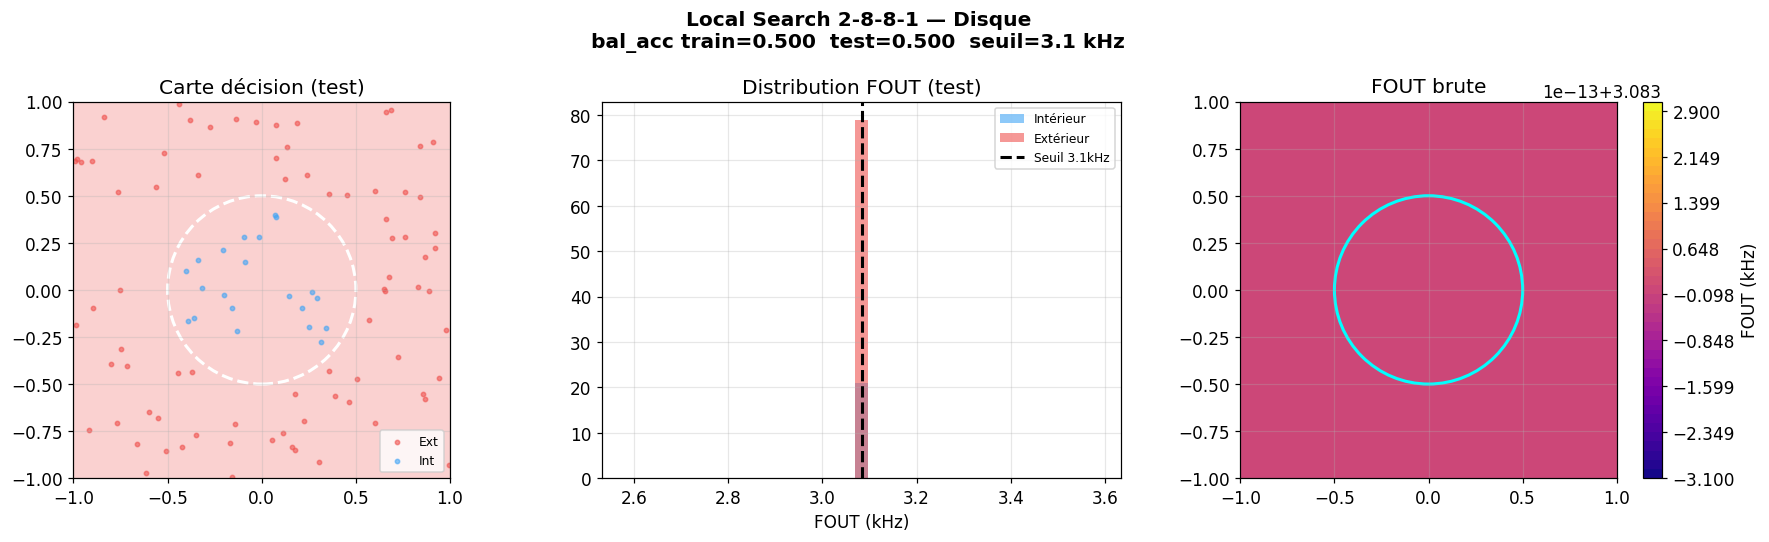

In [47]:
fig, axes = plt.subplots(1, 3, figsize=(17, 5))
fig.suptitle(f'Local Search 2-8-8-1 — Disque\n'
             f'bal_acc train={bal_tr:.3f}  test={bal_te:.3f}  '
             f'seuil={thr/1e3:.1f} kHz', fontweight='bold')

# Carte de décision
ax=axes[0]
res=40; xs=np.linspace(-1,1,res); XX,YY=np.meshgrid(xs,xs)
FG=np.zeros_like(XX)
for i in range(res):
    for j in range(res):
        vx,vy=xy_to_vmv(XX[i,j],YY[i,j])
        FG[i,j]=forward(vx,vy,global_best_w)
ax.contourf(XX,YY,(FG>thr).astype(int),levels=[-0.5,.5,1.5],
            colors=['#EF535044','#42A5F544'])
ax.contour(XX,YY,FG-thr,levels=[0],colors='k',linewidths=2)
ax.add_patch(plt.Circle((0,0),DISK_RADIUS,color='white',fill=False,lw=2,ls='--'))
ax.scatter(X_te[np.array(l_te)==-1,0],X_te[np.array(l_te)==-1,1],
           s=8,c='#EF5350',alpha=0.6,label='Ext')
ax.scatter(X_te[np.array(l_te)==+1,0],X_te[np.array(l_te)==+1,1],
           s=8,c='#42A5F5',alpha=0.6,label='Int')
ax.set_title('Carte décision (test)'); ax.set_aspect('equal')
ax.legend(fontsize=8); ax.grid(True,alpha=0.3)

# Distribution fréquences
ax=axes[1]
f_in  = [f for f,l in zip(f_te,l_te) if l==+1]
f_out = [f for f,l in zip(f_te,l_te) if l==-1]
bins  = np.linspace(min(f_te)-500,max(f_te)+500,40)
ax.hist(np.array(f_in)/1e3, bins=bins/1e3,alpha=0.6,color='#42A5F5',label='Intérieur')
ax.hist(np.array(f_out)/1e3,bins=bins/1e3,alpha=0.6,color='#EF5350',label='Extérieur')
ax.axvline(thr/1e3,color='k',lw=2,ls='--',label=f'Seuil {thr/1e3:.1f}kHz')
ax.set_xlabel('FOUT (kHz)'); ax.set_title('Distribution FOUT (test)')
ax.legend(fontsize=8); ax.grid(True,alpha=0.3)

# FOUT brute
ax=axes[2]
cf=ax.contourf(XX,YY,FG/1e3,levels=50,cmap='plasma')
plt.colorbar(cf,ax=ax,label='FOUT (kHz)')
ax.contour(XX,YY,FG-thr,levels=[0],colors='white',linewidths=2)
ax.add_patch(plt.Circle((0,0),DISK_RADIUS,color='cyan',fill=False,lw=2))
ax.set_title('FOUT brute'); ax.set_aspect('equal'); ax.grid(True,alpha=0.3)

plt.tight_layout(); plt.show()


In [48]:
rows=[]
for sn,en,in_ in SYNAPSES:
    e=global_best_w[en]; i=global_best_w[in_]
    if e>W_MIN:   mode,val='EXC',e
    elif i>W_MIN: mode,val='INH',i
    else:         mode,val='MIN',W_MIN
    rows.append({'synapse':sn,'e_param':en,'i_param':in_,
                 'mode':mode,'width_um':val,
                 'e_value':e,'i_value':i})

df_w=pd.DataFrame(rows)
df_w.to_csv('weights_disk_local_search.csv',index=False)
print("Poids exportés → weights_disk_local_search.csv")
print(f"Synapses actives (non-MIN): {(df_w['mode']!='MIN').sum()}/{len(df_w)}")
print()
print(df_w[df_w['mode']!='MIN'][['synapse','e_param','mode','width_um']].to_string(index=False))


Poids exportés → weights_disk_local_search.csv
Synapses actives (non-MIN): 0/88

Empty DataFrame
Columns: [synapse, e_param, mode, width_um]
Index: []
